# Fase 4 · Resultados y comunicación
**Airbnb en Santiago — Grupo 4 · MCDI500**

El análisis compara ocupación e ingresos estimados según comuna, configuración
y comodidades. Se utiliza la muestra procesada de F2, con las transformaciones
verificadas en F3. Los resultados describen asociaciones entre alojamientos
completos activos; no permiten calcular rentabilidad ni atribuir efectos causales.

## 1. Entorno y datos
El proyecto se instala con `python -m pip install -e .`. Las rutas parten de
la raíz del repositorio y las figuras conservan CLP, noches y porcentajes.

In [1]:
from pathlib import Path
import json
import sys
from datetime import date
from importlib.metadata import version

import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from src import visualizacion as viz
from src import comunicacion as com

RAIZ = Path("..") if Path.cwd().name == "F4" else Path(".")
DIR_PROCESADO = RAIZ / "data" / "processed"
DIR_DOCS = RAIZ / "docs"
DIR_FIGURAS = RAIZ / "F4" / "figuras"
SEMILLA = 42
com.estilo()
figuras = {}
tablas = {}
print("Python:", sys.version.split()[0], "| Entorno virtual:", sys.prefix != sys.base_prefix)
print({p: version(p) for p in ["pandas", "numpy", "matplotlib", "scipy", "seaborn"]})

df_procesado = pd.read_csv(DIR_PROCESADO / "listings_procesado.csv")
df = com.preparar_visual(df_procesado)
COLS_AMEN = [c for c in df if c.startswith("amen_")]
assert not {"name", "host_name", "comments", "reviewer_name", "listing_url"} & set(df.columns)
assert df[COLS_AMEN].isin([0, 1]).all().all()
assert df["host_id"].dropna().astype(str).str.fullmatch(r"[0-9a-f]{12}").all()
assert len(df) == len(df_procesado)
print(f"Procesado: {df_procesado.shape}; copia para visualizar: {df.shape}")

Python: 3.14.4 | Entorno virtual: True
{'pandas': '3.1.1', 'numpy': '2.5.4', 'matplotlib': '3.11.2', 'scipy': '1.18.1', 'seaborn': '0.13.2'}
Procesado: (3313, 64); copia para visualizar: (3313, 68)


La copia para visualizar agrega etiquetas de tamaño y comuna sin modificar
el procesado. Se mantienen los dormitorios imputados de F2. Los resultados
por tamaño incluyen esos casos y deben leerse con esa limitación.

## 2. Comunas
Las tablas reúnen las comunas con menos de 30 casos en **Otras comunas** y
calculan sus indicadores desde los registros originales. Los gráficos muestran
solo comunas individuales con n ≥ 30; la nota informa los casos excluidos.
Los segmentos representan P25–P75, no intervalos de confianza.

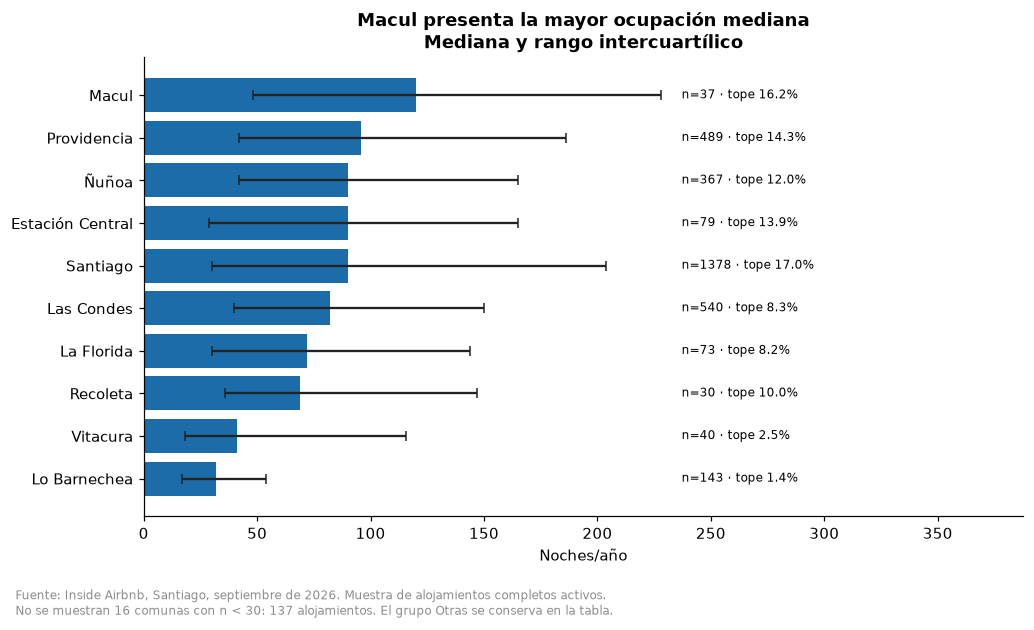

**Lectura.** Las medianas se comparan junto con su dispersión; el porcentaje en el tope identifica la censura de cada grupo.

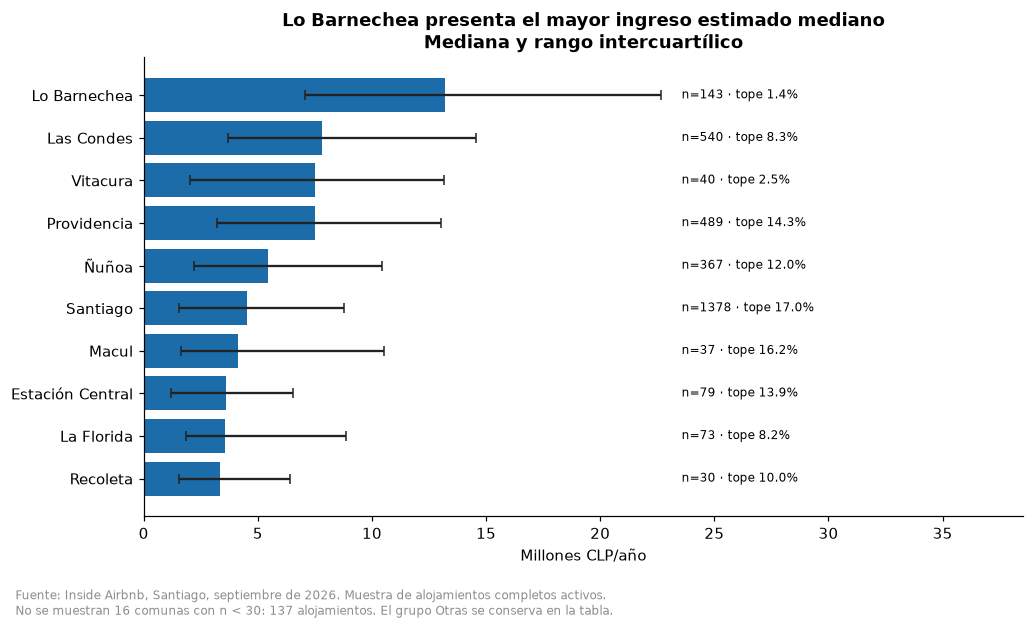

**Lectura.** Los ingresos medianos no representan rentabilidad. El segmento P25–P75 muestra diferencias entre alojamientos de una misma comuna.

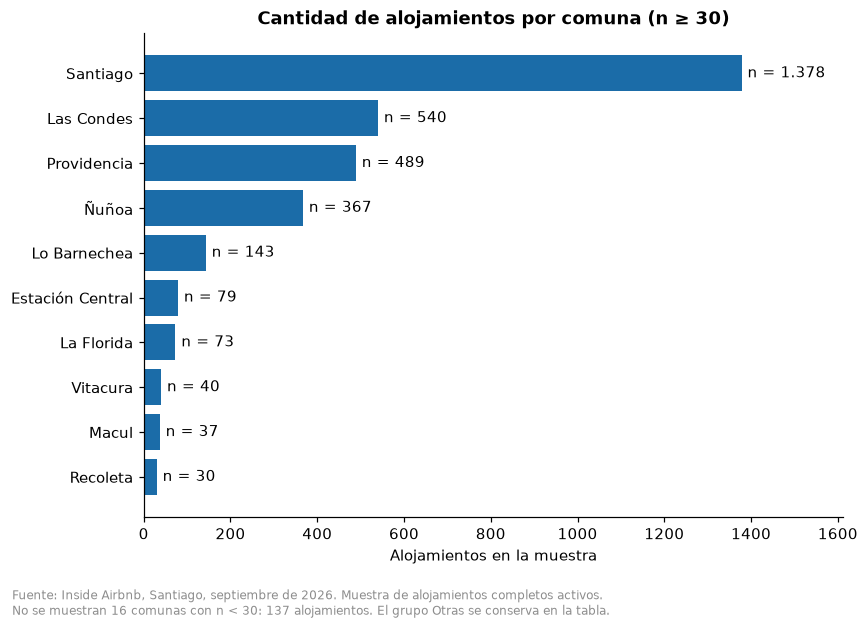

**Lectura.** Santiago concentra la mayor cantidad de casos. Los conteos corresponden a la muestra, no a la oferta total de cada comuna.

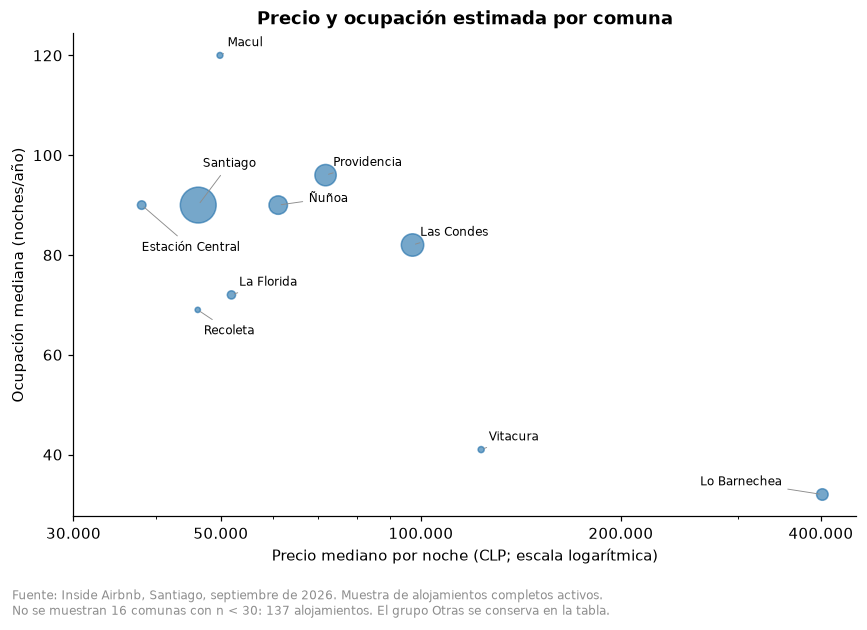

**Lectura.** Una comuna con precio mediano mayor no necesariamente presenta mayor ocupación. El tamaño del punto representa su número de casos.

,comuna_agrupada,n,ocupacion_mediana,ocupacion_q1,ocupacion_q3,pct_en_tope,precio_mediano,precio_q1,precio_q3,ingresos_medianos,ingresos_q1,ingresos_q3,ingreso_huesped_mediano,ingreso_dormitorio_mediano
4,Macul,37,120.0,48.0,228.0,0.16,49840.00,41500.00,52800.00,4141032.0,1620000.0,10527930.0,1817424.00,4248516.00
6,Providencia,489,96.0,42.0,186.0,0.14,71870.00,57500.00,91834.00,7500000.0,3229156.0,13005000.0,2389392.00,5521356.00
0,Estación Central,79,90.0,29.0,165.0,0.14,38000.00,34213.00,46285.50,3591000.0,1200042.0,6535710.0,1209060.00,2828280.00
10,Ñuñoa,367,90.0,42.0,165.0,0.12,60992.00,49625.50,73421.25,5461437.0,2202000.0,10429522.5,1744846.00,4053291.00
8,Santiago,1378,90.0,30.0,204.0,0.17,46227.00,38000.00,59196.25,4508718.0,1536447.0,8774514.0,1558050.00,3752985.75
2,Las Condes,540,82.0,40.0,150.0,0.08,97143.25,77880.00,118473.62,7800000.0,3671640.0,14578918.5,2515491.80,5869040.00
1,La Florida,73,72.0,30.0,144.0,0.08,51864.00,44283.00,65000.00,3568530.0,1860000.0,8866554.0,1350000.00,3104379.00
7,Recoleta,30,69.0,36.0,147.0,0.10,46149.50,37800.00,66454.00,3324129.0,1543789.5,6419212.5,1208790.00,3144258.00
5,Otras comunas,137,60.0,24.0,138.0,0.12,50000.00,42000.00,70000.00,3211098.0,1350000.0,8071056.0,1121040.00,2475125.00
9,Vitacura,40,41.0,18.0,115.5,0.02,123226.38,100936.75,152970.50,7504074.0,2025000.0,13145380.5,1440523.40,2544029.00


In [2]:
resumen_comuna = com.tabla_comunas(df)
tablas["reporte_comunas_mediana_IQR"] = resumen_comuna
figs_comunas = com.figuras_comunas(df, resumen_comuna)
figuras.update(figs_comunas)
com.mostrar(figs_comunas)
display(resumen_comuna.round(2))
assert resumen_comuna["n"].sum() == len(df)

In [3]:
individuales = resumen_comuna[resumen_comuna["comuna_agrupada"] != "Otras comunas"]
mayor_ocup = individuales.loc[individuales["ocupacion_mediana"].idxmax()]
mayor_ing = individuales.loc[individuales["ingresos_medianos"].idxmax()]
display(Markdown(
    f"**Lectura.** {mayor_ocup['comuna_agrupada']} presenta la mayor ocupación mediana "
    f"({mayor_ocup['ocupacion_mediana']:.0f} noches; n={int(mayor_ocup['n'])}). "
    f"{mayor_ing['comuna_agrupada']} encabeza los ingresos medianos "
    f"({mayor_ing['ingresos_medianos']/1e6:.2f} millones CLP/año). "
    "No es el mismo indicador: un ingreso mayor puede acompañar un precio por noche mayor. "
    "El grupo Otras no identifica una ubicación concreta."))

**Lectura.** Macul presenta la mayor ocupación mediana (120 noches; n=37). Lo Barnechea encabeza los ingresos medianos (13.18 millones CLP/año). No es el mismo indicador: un ingreso mayor puede acompañar un precio por noche mayor. El grupo Otras no identifica una ubicación concreta.

## 3. Dormitorios, baños y capacidad
Se comparan ocupación, precio e ingresos estimados para los tres ejes. El ingreso
por huésped usa la **capacidad anunciada** como divisor, no el número real de
huéspedes alojados. Los estudios no tienen ingreso por dormitorio porque su
número de dormitorios es cero. Los tamaños de grupo y la censura se conservan
en las tablas, incluidos los grupos pequeños.

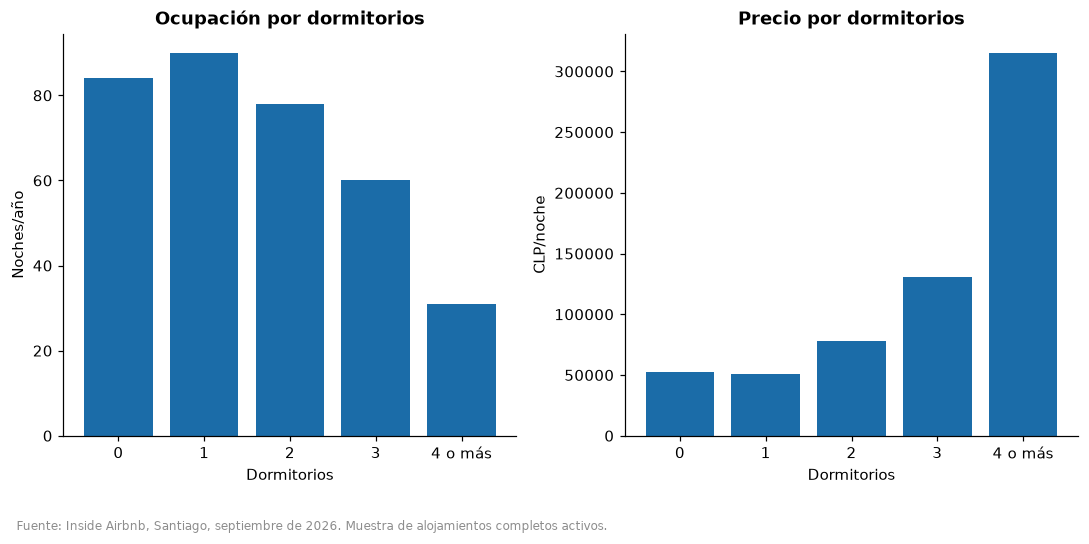

**Lectura.** El precio crece con los dormitorios, pero la ocupación no sigue el mismo patrón.

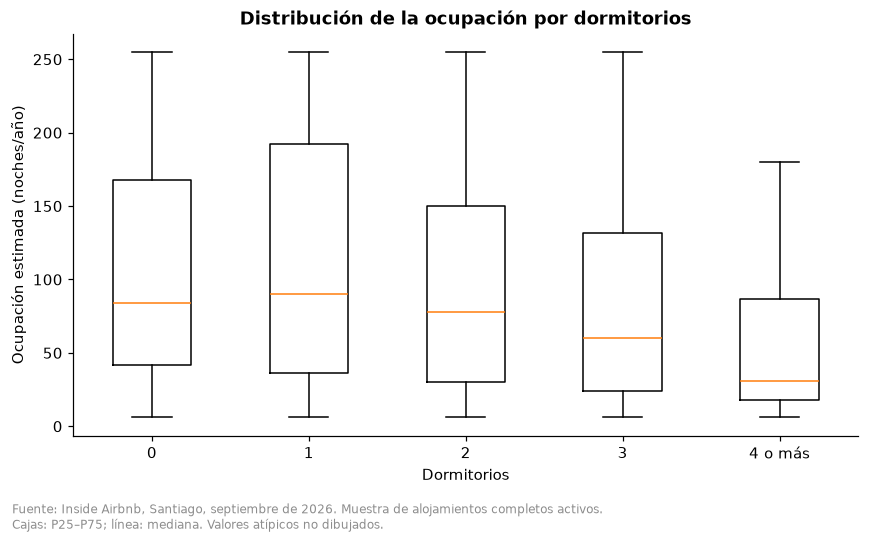

**Lectura.** Las cajas permiten comparar dispersión y no solo medianas. La variable permanece limitada a 255 noches.

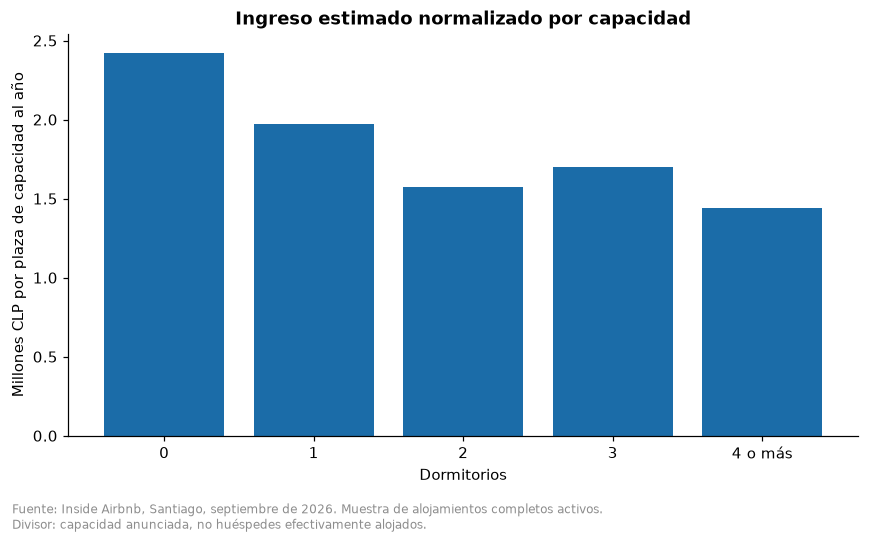

**Lectura.** La normalización cambia la comparación respecto del ingreso total: las unidades grandes no encabezan el ingreso por plaza.

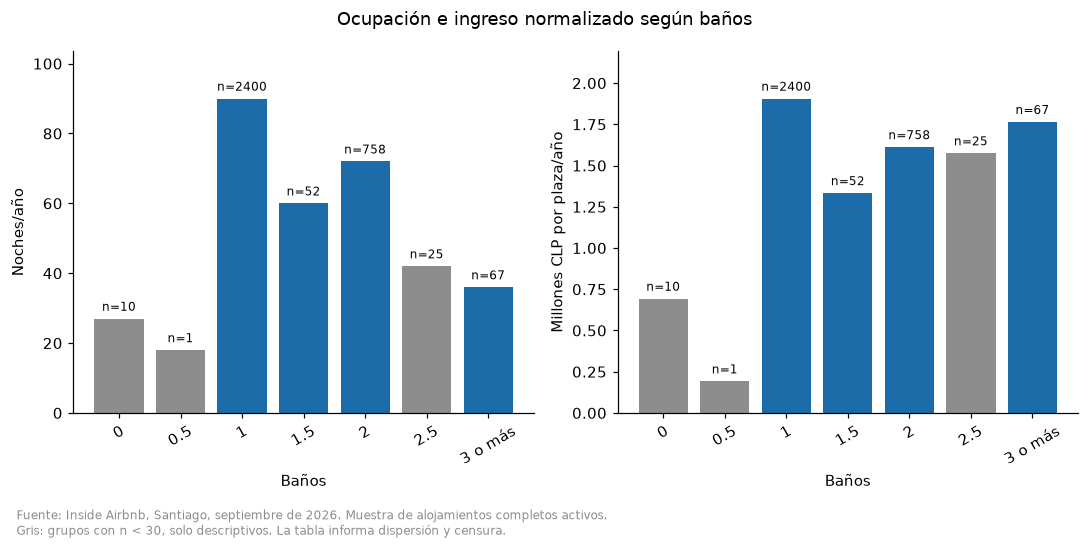

**Lectura.** Baños se compara sin separar comuna y tamaño. Estas diferencias no permiten atribuir un efecto al número de baños.

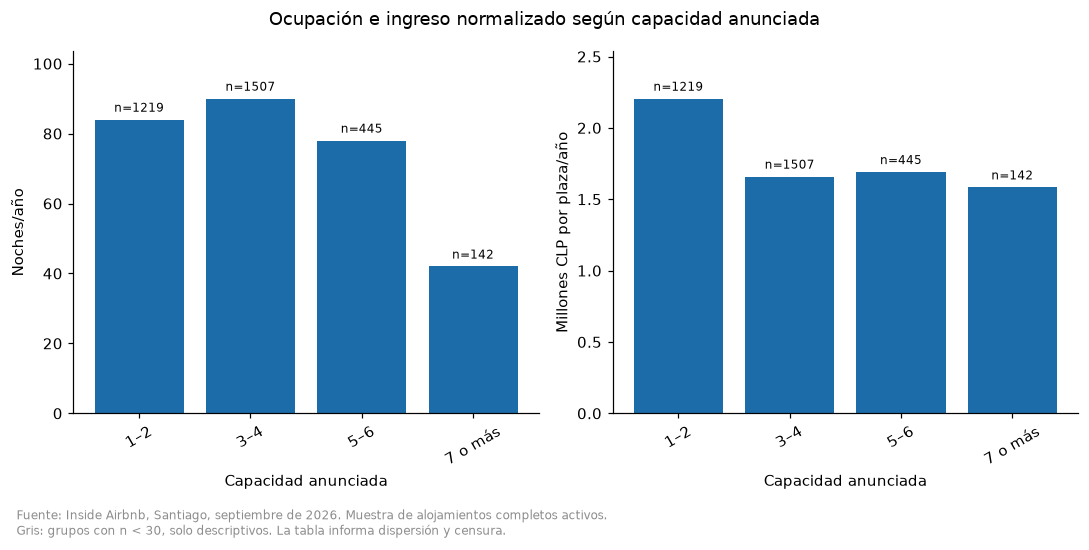

**Lectura.** La capacidad anunciada permite normalizar ingresos, pero no informa cuántos huéspedes se alojaron efectivamente.

DORMITORIOS


,dormitorios_grupo,n,ocupacion_mediana,ocupacion_q1,ocupacion_q3,pct_en_tope,precio_mediano,precio_q1,precio_q3,ingresos_medianos,ingresos_q1,ingresos_q3,ingreso_huesped_mediano,ingreso_dormitorio_mediano
0,0,77,84.0,42.0,168.0,0.13,52316.00,40804.50,80744.00,6103944.0,1998120.0,9832104.00,2422320.00,NaN
1,1,2122,90.0,36.0,192.0,0.15,51071.00,40349.00,68000.00,4953000.0,1855899.0,9299550.00,1975093.75,4953000.00
2,2,874,78.0,30.0,150.0,0.09,78127.00,59278.25,108217.25,6473800.0,2628750.0,12930732.00,1570538.00,3236900.00
3,3,164,60.0,24.0,132.0,0.10,130973.08,95696.17,214752.38,10375422.0,4230630.0,21936564.00,1703000.00,3458474.00
4,4 o más,76,31.0,18.0,87.0,0.05,315301.00,149231.00,564852.00,11364495.0,5850000.0,23591532.75,1437497.10,2678472.48


BANOS


,banos_grupo,n,ocupacion_mediana,ocupacion_q1,ocupacion_q3,pct_en_tope,precio_mediano,precio_q1,precio_q3,ingresos_medianos,ingresos_q1,ingresos_q3,ingreso_huesped_mediano,ingreso_dormitorio_mediano
0,0,10,27.0,19.5,52.5,0.10,51205.50,38125.00,69175.00,1597308.0,1021710.0,2107500.00,693345.00,1385550.00
1,0.5,1,18.0,18.0,18.0,0.00,32000.00,32000.00,32000.00,576000.0,576000.0,576000.00,192000.00,576000.00
2,1,2400,90.0,36.0,192.0,0.15,52050.25,40989.00,69779.25,5087748.0,1879492.5,9484940.75,1906290.00,4617000.00
3,1.5,52,60.0,28.5,114.0,0.04,106050.25,59794.35,139015.38,5681454.0,3288645.0,11004275.25,1333521.00,3066360.00
4,2,758,72.0,30.0,150.0,0.08,90000.00,66305.25,123919.00,7428254.0,2952879.0,14675304.00,1612211.40,3484557.25
5,2.5,25,42.0,24.0,140.0,0.12,161882.00,126600.00,228674.00,7945317.0,3885168.0,17907720.00,1575000.00,2996091.00
6,3 o más,67,36.0,19.0,96.0,0.04,375000.00,185365.25,630680.16,14552544.0,7610021.0,24283350.00,1764941.92,4247336.00


CAPACIDAD


,capacidad_grupo,n,ocupacion_mediana,ocupacion_q1,ocupacion_q3,pct_en_tope,precio_mediano,precio_q1,precio_q3,ingresos_medianos,ingresos_q1,ingresos_q3,ingreso_huesped_mediano,ingreso_dormitorio_mediano
0,1–2,1219,84.0,30.0,174.0,0.13,50000.0,40075.50,65709.0,4314816.0,1704525.0,8857071.0,2205000.00,4248834.00
1,3–4,1507,90.0,36.0,186.0,0.15,59363.0,45000.00,80355.0,5829252.0,2131740.0,10228791.0,1659000.00,4323470.25
2,5–6,445,78.0,30.0,174.0,0.11,100000.0,70712.00,137751.0,8781474.0,3326760.0,16500000.0,1691000.00,4107165.75
3,7 o más,142,42.0,18.0,102.0,0.06,298927.5,145871.38,538250.0,13077360.0,6381804.0,24998722.5,1583709.69,4212067.00


In [4]:
configuracion = com.tablas_configuracion(df)
figs_configuracion = com.figuras_configuracion(df, configuracion)
figuras.update(figs_configuracion)
com.mostrar(figs_configuracion)
for eje, tabla in configuracion.items():
    tablas["configuracion_" + eje] = tabla
    print(eje.upper())
    display(tabla.round(2))

In [5]:
dorm = configuracion["dormitorios"].set_index("dormitorios_grupo")
r1, r3 = dorm.loc["1"], dorm.loc["3"]
display(Markdown(
    f"**Lectura.** Un dormitorio presenta {r1['ocupacion_mediana']:.0f} noches de ocupación mediana "
    f"e ingresos por plaza de {r1['ingreso_huesped_mediano']/1e6:.2f} millones CLP/año; "
    f"tres dormitorios presentan {r3['ocupacion_mediana']:.0f} noches y "
    f"{r3['ingreso_huesped_mediano']/1e6:.2f} millones por plaza. "
    "El ingreso total y el normalizado responden preguntas distintas. "
    "Estas diferencias no prueban que el tamaño sea su causa ni que una unidad sea más rentable."))
for eje in ["banos", "capacidad"]:
    t = configuracion[eje]
    elegibles = t[t["n"] >= 30]
    if not elegibles.empty:
        fila = elegibles.loc[elegibles["ocupacion_mediana"].idxmax()]
        display(Markdown(f"**{eje.capitalize()}.** Entre los grupos con n ≥ 30, "
                         f"{fila[eje + '_grupo']} presenta la mayor ocupación mediana "
                         f"({fila['ocupacion_mediana']:.0f} noches; n={int(fila['n'])}). "
                         "La comparación no separa el efecto de comuna, precio y tamaño."))

**Lectura.** Un dormitorio presenta 90 noches de ocupación mediana e ingresos por plaza de 1.98 millones CLP/año; tres dormitorios presentan 60 noches y 1.70 millones por plaza. El ingreso total y el normalizado responden preguntas distintas. Estas diferencias no prueban que el tamaño sea su causa ni que una unidad sea más rentable.

**Banos.** Entre los grupos con n ≥ 30, 1 presenta la mayor ocupación mediana (90 noches; n=2400). La comparación no separa el efecto de comuna, precio y tamaño.

**Capacidad.** Entre los grupos con n ≥ 30, 3–4 presenta la mayor ocupación mediana (90 noches; n=1507). La comparación no separa el efecto de comuna, precio y tamaño.

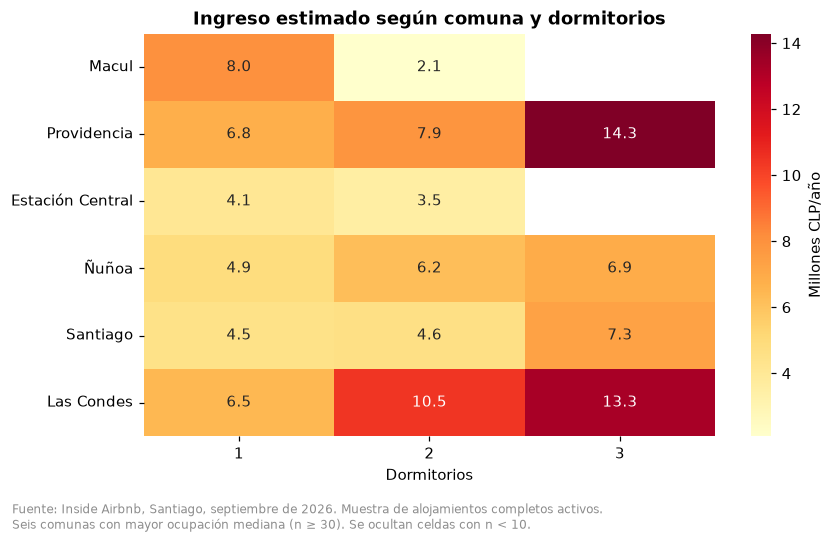

**Lectura.** No se interpreta una celda sin revisar su tamaño; se ocultan las combinaciones con menos de diez casos.

bedrooms,1.0,2.0,3.0
comuna_agrupada,,,
Macul,26,10,0
Providencia,297,134,29
Estación Central,56,21,0
Ñuñoa,240,106,14
Santiago,1029,285,28
Las Condes,307,174,33


In [6]:
fig_cruce, conteos = com.figura_cruce(df, resumen_comuna)
figuras["fig4_ingresos_comuna_dormitorios"] = fig_cruce
com.mostrar({"fig4_ingresos_comuna_dormitorios": fig_cruce})
display(conteos)
tablas["conteos_comuna_dormitorios"] = conteos.reset_index()

**Lectura.** El cruce permite comparar dormitorios dentro de una misma comuna.
Las celdas con menos de diez alojamientos no se colorean: sus medianas no
sustentan una recomendación. El umbral de 30 de una comuna no garantiza que
cada combinación de comuna y tamaño tenga suficientes casos.

## 4. Comodidades y cuartil superior de ocupación
El grupo superior incluye ocupación **≥ P75**, con todos los empates. Se compara
la prevalencia de las 20 comodidades declaradas frente al resto. Los puntos
muestran diferencias en puntos porcentuales e IC individuales del 95 %
(Newcombe-Wilson; Newcombe, 1998). La prueba exacta de Fisher usa Bonferroni para las veinte
comparaciones; los intervalos dibujados no son simultáneos.

La muestra es estratificada y los alojamientos pueden compartir anfitrión.
Los intervalos suponen independencia y no incorporan ese diseño: son una
aproximación exploratoria, no una garantía sobre el universo.

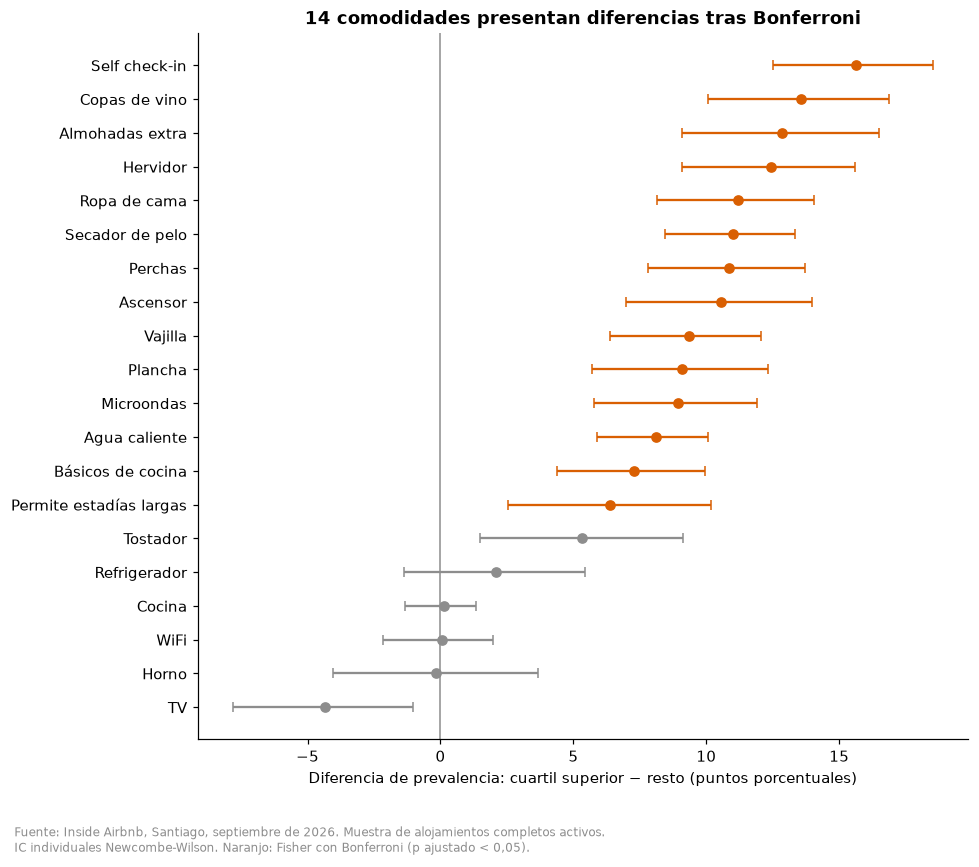

**Lectura.** Los puntos describen equipamiento declarado. El color refleja el contraste ajustado, no causalidad ni preferencia.

,comodidad,n_top,n_resto,frec_top,frec_resto,diferencia,ic_inf,ic_sup,p_valor,p_ajustado,significativa_bonf,ocup_con,ocup_sin
10,self_check_in,858,2455,0.85082,0.69450,0.15631,0.12524,0.18528,0.00000,0.00000,True,96.0,48.0
14,wine_glasses,858,2455,0.76807,0.63259,0.13548,0.10056,0.16865,0.00000,0.00000,True,96.0,60.0
16,extra_pillows_and_blankets,858,2455,0.67599,0.54745,0.12854,0.09098,0.16485,0.00000,0.00000,True,96.0,60.0
13,hot_water_kettle,858,2455,0.79720,0.67291,0.12429,0.09069,0.15602,0.00000,0.00000,True,96.0,54.0
7,bed_linens,858,2455,0.85082,0.73890,0.11192,0.08136,0.14039,0.00000,0.00000,True,96.0,48.0
3,hair_dryer,858,2455,0.91608,0.80611,0.10997,0.08451,0.13321,0.00000,0.00000,True,96.0,36.0
6,hangers,858,2455,0.84965,0.74094,0.10871,0.07812,0.13723,0.00000,0.00000,True,96.0,48.0
15,elevator,858,2455,0.73893,0.63340,0.10553,0.06976,0.13974,0.00000,0.00000,True,96.0,58.0
5,dishes_and_silverware,858,2455,0.86364,0.77026,0.09337,0.06392,0.12070,0.00000,0.00000,True,90.0,48.0
12,iron,858,2455,0.77972,0.68880,0.09092,0.05683,0.12326,0.00000,0.00001,True,96.0,54.0


P75: 174; superior: 858; resto: 2455


In [7]:
en_top = viz.cuartil_superior(df)
comp = viz.comparar_amenidades(df, en_top, COLS_AMEN)
tablas["comparacion_comodidades"] = comp
fig_amen = com.figura_amenidades(comp)
figuras["fig5_comodidades_cuartil_superior"] = fig_amen
com.mostrar({"fig5_comodidades_cuartil_superior": fig_amen})
display(comp.round(5))
print(f"P75: {df[viz.OCUPACION].quantile(.75):.0f}; superior: {en_top.sum()}; resto: {(~en_top).sum()}")

In [8]:
self_check = comp.set_index("comodidad").loc["self_check_in"]
display(Markdown(
    f"**Lectura.** Self check-in presenta una diferencia de {self_check['diferencia']*100:.1f} pp "
    f"(IC 95 %: {self_check['ic_inf']*100:.1f} a {self_check['ic_sup']*100:.1f}). "
    f"{int(comp['significativa_bonf'].sum())} de {len(comp)} comodidades cumplen el umbral ajustado. "
    "La asociación no demuestra preferencia del huésped ni profesionalización del anfitrión; "
    "tampoco indica cuánto cambiaría la ocupación al instalar una comodidad."))

**Lectura.** Self check-in presenta una diferencia de 15.6 pp (IC 95 %: 12.5 a 18.5). 14 de 20 comodidades cumplen el umbral ajustado. La asociación no demuestra preferencia del huésped ni profesionalización del anfitrión; tampoco indica cuánto cambiaría la ocupación al instalar una comodidad.

### Revisión de confusión
Se mantiene el mismo umbral P75 global y se repite la comparación dentro de
cada comuna y tramo de capacidad (1–2, 3–4 y 5 o más). Se exige un mínimo de
diez casos en cada grupo. El ajuste de Bonferroni abarca todas las pruebas
retenidas en esta revisión. Los estratos excluidos no ofrecen evidencia a
favor ni en contra de una asociación.

In [9]:
confusion = viz.comparar_por_estratos(df, COLS_AMEN)
tablas["comodidades_por_estratos"] = confusion
resumen_confusion = viz.resumir_estratos(confusion)
tablas["resumen_comodidades_estratos"] = resumen_confusion
display(resumen_confusion.round(4))
if not confusion.empty:
    display(confusion[confusion["comodidad"] == "self_check_in"].round(4))
    self_estratos = confusion[confusion["comodidad"] == "self_check_in"]
    display(Markdown(
        f"**Lectura.** Self check-in tiene diferencia positiva en "
        f"{int((self_estratos['diferencia'] > 0).sum())} de {len(self_estratos)} estratos evaluables; "
        f"{int(self_estratos['significativa_bonf'].sum())} cumplen el umbral ajustado. "
        "La comparación por estratos reduce parte de la confusión, pero no controla "
        "precio, gestión, ubicación específica u otras variables no medidas."))

,comodidad,estratos,diferencias_positivas,significativas_bonf,diferencia_minima,diferencia_maxima
0,bed_linens,14,13,0,-0.0394,0.3387
1,cooking_basics,14,14,0,0.0164,0.3688
2,dishes_and_silverware,14,13,0,-0.1320,0.3102
3,elevator,14,11,0,-0.1576,0.1923
4,extra_pillows_and_blankets,14,12,1,-0.0485,0.3945
5,hair_dryer,14,13,0,-0.0102,0.2750
6,hangers,14,11,0,-0.1033,0.3710
7,hot_water,14,13,0,-0.0062,0.3065
8,hot_water_kettle,14,14,0,0.0156,0.3747
9,iron,14,12,0,-0.1177,0.2688


,comodidad,n_top,n_resto,frec_top,frec_resto,diferencia,ic_inf,ic_sup,p_valor,p_ajustado,significativa_bonf,ocup_con,ocup_sin,comuna,capacidad
14,self_check_in,10,32,0.8000,0.7500,0.0500,-0.2814,0.2732,1.0000,1.0000,False,99.0,22.0,Estación Central,3–4
23,self_check_in,31,139,0.7742,0.6978,0.0764,-0.1097,0.2143,0.5121,1.0000,False,90.0,42.0,Las Condes,1–2
52,self_check_in,45,186,0.8889,0.8118,0.0771,-0.0564,0.1654,0.2758,1.0000,False,88.0,48.0,Las Condes,3–4
60,self_check_in,35,104,0.9714,0.7212,0.2503,0.1103,0.3461,0.0015,0.4123,False,114.0,54.0,Las Condes,5 o más
85,self_check_in,13,62,0.8462,0.5161,0.3300,0.0360,0.4944,0.0340,1.0000,False,114.0,24.0,Otras comunas,3–4
115,self_check_in,47,143,0.7447,0.7273,0.0174,-0.1373,0.1466,1.0000,1.0000,False,96.0,60.0,Providencia,1–2
120,self_check_in,64,146,0.9062,0.6644,0.2419,0.1221,0.3362,0.0002,0.0427,True,120.0,60.0,Providencia,3–4
142,self_check_in,31,58,0.8710,0.6552,0.2158,0.0225,0.3660,0.0436,1.0000,False,120.0,81.0,Providencia,5 o más
162,self_check_in,178,426,0.8427,0.7160,0.1267,0.0537,0.1909,0.0009,0.2501,False,102.0,54.0,Santiago,1–2
182,self_check_in,211,434,0.8720,0.7604,0.1117,0.0476,0.1689,0.0008,0.2292,False,105.0,54.0,Santiago,3–4


**Lectura.** Self check-in tiene diferencia positiva en 14 de 14 estratos evaluables; 1 cumplen el umbral ajustado. La comparación por estratos reduce parte de la confusión, pero no controla precio, gestión, ubicación específica u otras variables no medidas.

## 5. Reseñas: menciones, contexto e idioma
Se conserva el agregado anónimo por alojamiento de los últimos doce meses.
Las menciones se detectan con diccionarios; el contexto negativo, con palabras
cercanas a cada mención. Son indicadores exploratorios sin validación manual.
Una ausencia de mención no prueba indiferencia y una coincidencia negativa
no constituye por sí sola una queja. El idioma inferido no identifica
nacionalidad ni demanda extranjera.

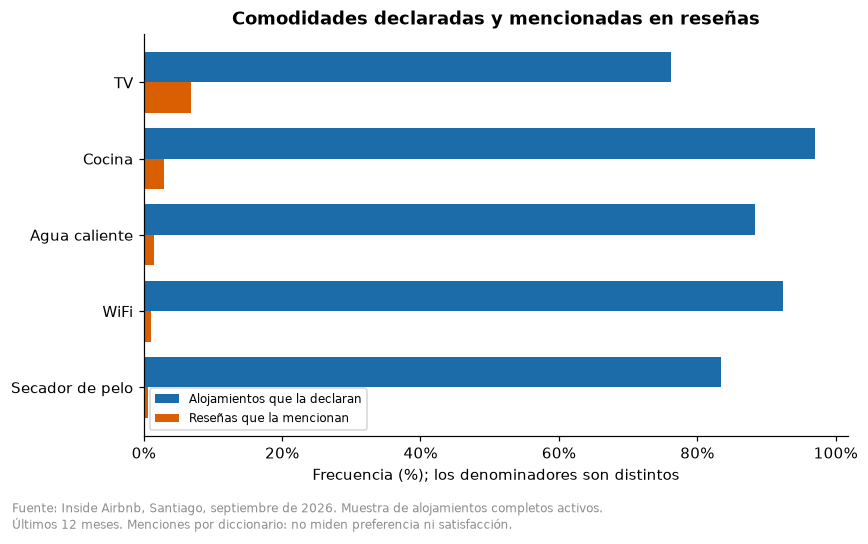

**Lectura.** Declarar y mencionar una comodidad usan denominadores distintos. Su contraste no mide satisfacción.

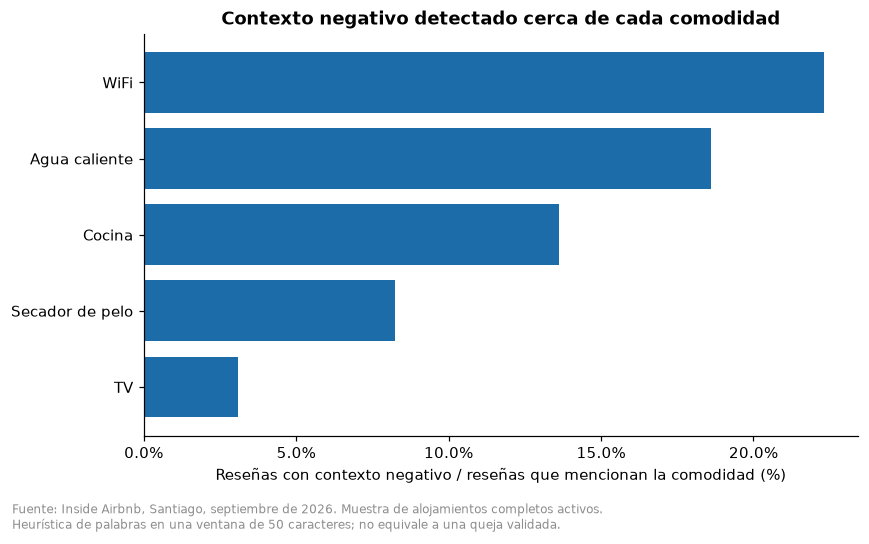

**Lectura.** El contexto negativo es una detección por reglas; requiere revisión manual antes de interpretarse como queja.

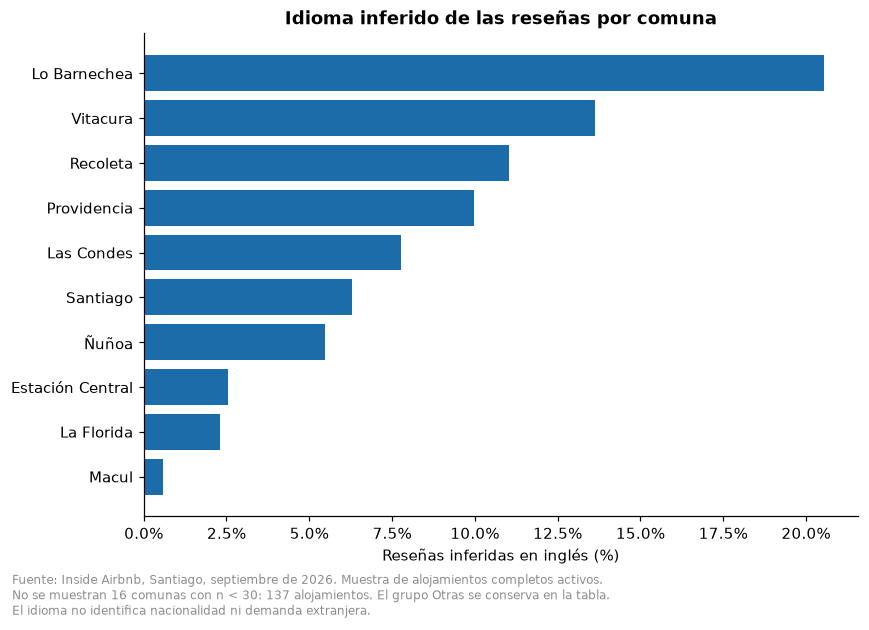

**Lectura.** La proporción se pondera por cantidad de reseñas. Idioma inferido no equivale a nacionalidad.

,comodidad,declarada,mencionada,menciones,pct_queja
9,wine_glasses,0.6677,0.0000,1.0,0.0000
13,toaster,0.5560,0.0006,39.0,0.2308
6,self_check_in,0.7350,0.0011,74.0,0.0135
5,microwave,0.7612,0.0013,87.0,0.1954
11,long_term_stays_allowed,0.5575,0.0014,95.0,0.0316
12,oven,0.5560,0.0019,129.0,0.3178
7,refrigerator,0.7292,0.0020,132.0,0.1970
8,iron,0.7123,0.0020,135.0,0.1037
10,elevator,0.6607,0.0024,163.0,0.1534
3,hair_dryer,0.8346,0.0058,389.0,0.0823


,resenas_ingles,n_resenas,pct_en
comuna_agrupada,,,
Estación Central,45.0,1764,0.0255
La Florida,30.0,1307,0.0230
Las Condes,756.0,9712,0.0778
Lo Barnechea,189.0,920,0.2054
Macul,5.0,857,0.0058
Otras comunas,128.0,2759,0.0464
Providencia,1026.0,10283,0.0998
Recoleta,56.0,507,0.1105
Santiago,1977.0,31485,0.0628


In [10]:
res_agg = pd.read_csv(DIR_PROCESADO / "resenas_por_listing.csv")
df_resenas = com.unir_resenas(df, res_agg)
comparacion = com.resumen_resenas(df_resenas)
idiomas = com.idioma_comunas(df_resenas)
tablas["resenas_comodidades"] = comparacion
tablas["idioma_comunas"] = idiomas.reset_index()
figs_resenas = com.figuras_resenas(df_resenas, comparacion, idiomas)
figuras.update(figs_resenas)
com.mostrar(figs_resenas)
display(comparacion.round(4))
display(idiomas.round(4))

**Lectura.** Las frecuencias declaradas usan alojamientos como denominador;
las menciones usan reseñas. No son medidas equivalentes de valoración.
El contexto negativo orienta una revisión de mantenimiento, sin demostrar
qué mejora aumentaría la ocupación. Las diferencias de idioma describen el
texto de quienes dejaron reseña, no a todos los huéspedes.

## 6. Síntesis y limitaciones
Los departamentos de un dormitorio presentan mayor ocupación mediana e
ingreso por plaza que los de tres dormitorios en el conjunto observado.
Las unidades grandes presentan mayor ingreso total. Providencia y Las Condes
son ubicaciones a comparar por ingreso y precio, no una recomendación de
compra demostrada. La decisión requiere precio de adquisición, costos y
validación adicional del mercado.

Como perfil para profundizar, se propone comparar viviendas de uno a dos
dormitorios en Providencia o Las Condes, sin convertir ese perfil en una
recomendación de compra ni en una promesa de retorno.

El equipamiento se asocia al desempeño, pero ninguna comodidad puede
recomendarse como causa de mayor ocupación. Self check-in queda como una
asociación observada, no como preferencia comprobada ni indicador validado
de gestión profesional.

- La ocupación se estima a partir de reseñas; no corresponde a reservas observadas.
- El tope de 255 noches impide distinguir ocupaciones superiores. Puede subestimar
  valores del cuartil superior; su efecto sobre cada cuantil depende de la censura.
- `Entire home/apt` también incluye casas; el análisis no se limita exclusivamente a departamentos.
- Solo se consideran anuncios completos activos: existe sesgo de supervivencia.
- La muestra estratificada y una sola captura no permiten extrapolar totales ni
  describir estacionalidad. No se usan ponderadores para estimar el universo.
- Los ingresos estimados no son rentabilidad: faltan compra, gastos y comisiones.
- El análisis de reseñas utiliza reglas en español e inglés y no tiene validación
  manual. Las menciones pueden omitir variantes, ironía o negaciones.

La conclusión es descriptiva: sirve para acotar perfiles que conviene estudiar,
no para garantizar un retorno de inversión.

## 7. Evidencia y exportación
Las tablas y figuras se regeneran desde el módulo. Cada cifra de la tabla de
hallazgos identifica la celda que la produce mediante un ID estable. El informe
y el video deben usar esta misma ejecución.

In [11]:
hallazgos = pd.DataFrame([
    {"eje": "Comuna", "hallazgo": "Mayor ocupación mediana entre comunas con n ≥ 30",
     "grupo": mayor_ocup["comuna_agrupada"], "valor": mayor_ocup["ocupacion_mediana"],
     "unidad": "noches/año", "n": mayor_ocup["n"], "celda_id": "f4-comunas", "figura": "fig1_ocupacion_comuna"},
    {"eje": "Comuna", "hallazgo": "Mayor ingreso mediano entre comunas con n ≥ 30",
     "grupo": mayor_ing["comuna_agrupada"], "valor": mayor_ing["ingresos_medianos"],
     "unidad": "CLP/año", "n": mayor_ing["n"], "celda_id": "f4-comunas", "figura": "fig1b_ingresos_comuna"},
    {"eje": "Configuración", "hallazgo": "Ingreso mediano por plaza de capacidad",
     "grupo": "1 dormitorio", "valor": r1["ingreso_huesped_mediano"],
     "unidad": "CLP/plaza/año", "n": r1["n"], "celda_id": "f4-configuracion", "figura": "fig3b_ingreso_huesped_dormitorios"},
    {"eje": "Comodidades", "hallazgo": "Diferencia de prevalencia; IC individual del 95 %",
     "grupo": "self_check_in", "valor": self_check["diferencia"]*100,
     "unidad": "puntos porcentuales", "n": len(df), "celda_id": "f4-comodidades", "figura": "fig5_comodidades_cuartil_superior",
     "ic_inf": self_check["ic_inf"]*100, "ic_sup": self_check["ic_sup"]*100},
])
hallazgos["n"] = hallazgos["n"].astype(int)
hallazgos["notebook"] = "F4/S3_F4_Visualizacion_Comunicacion.ipynb"
tablas["hallazgos_f4"] = hallazgos
rutas = com.exportar(figuras, tablas, DIR_FIGURAS, DIR_DOCS)
metadatos = {
    "fase": "F4", "fecha_ejecucion": str(date.today()), "semilla": SEMILLA,
    "python": sys.version.split()[0],
    "dependencias": {p: version(p) for p in ["numpy", "pandas", "matplotlib", "scipy", "seaborn"]},
    "entradas": ["data/processed/listings_procesado.csv", "data/processed/resenas_por_listing.csv"],
    "figuras": [Path(r).relative_to(RAIZ).as_posix() for r in rutas.values()],
    "minimo_comuna": 30, "cuartil_superior": ">= P75 con empates", "n": len(df),
    "tope_255_n": int((df[viz.OCUPACION] == 255).sum()),
    "comparacion": "IC Newcombe-Wilson individual; Fisher y Bonferroni",
    "fuente_hallazgos": "docs/hallazgos_f4.csv",
    "celdas_hallazgos": hallazgos["celda_id"].tolist(),
}
(DIR_DOCS / "metadatos_f4.json").write_text(json.dumps(metadatos, ensure_ascii=False, indent=2), encoding="utf-8")
display(hallazgos)
print(f"Exportadas {len(rutas)} figuras y {len(tablas)} tablas.")

,eje,hallazgo,grupo,valor,unidad,n,celda_id,figura,ic_inf,ic_sup,notebook
0,Comuna,Mayor ocupación mediana entre comunas con n ≥ 30,Macul,1.200000e+02,noches/año,37,f4-comunas,fig1_ocupacion_comuna,NaN,NaN,F4/S3_F4_Visualizacion_Comunicacion.ipynb
1,Comuna,Mayor ingreso mediano entre comunas con n ≥ 30,Lo Barnechea,1.318278e+07,CLP/año,143,f4-comunas,fig1b_ingresos_comuna,NaN,NaN,F4/S3_F4_Visualizacion_Comunicacion.ipynb
2,Configuración,Ingreso mediano por plaza de capacidad,1 dormitorio,1.975094e+06,CLP/plaza/año,2122,f4-configuracion,fig3b_ingreso_huesped_dormitorios,NaN,NaN,F4/S3_F4_Visualizacion_Comunicacion.ipynb
3,Comodidades,Diferencia de prevalencia; IC individual del 95 %,self_check_in,1.563148e+01,puntos porcentuales,3313,f4-comodidades,fig5_comodidades_cuartil_superior,12.523781,18.527724,F4/S3_F4_Visualizacion_Comunicacion.ipynb


Exportadas 14 figuras y 11 tablas.


## Respuesta a la retroalimentación

| Observación | Corrección o evidencia |
|---|---|
| Comunas pequeñas e indicadores inestables | Otras en tablas; gráficos individuales con n ≥ 30 y nota de exclusión. Mediana, P25–P75 y n en `f4-comunas`. |
| Tamaño e ingresos | Dormitorios, baños y capacidad; ingreso total y normalizado en `f4-configuracion`. |
| Comodidades y comparaciones múltiples | Diferencias en pp, IC individuales y Fisher–Bonferroni en `f4-comodidades`. |
| Confusión | Comparación por comuna y capacidad con P75 global en `f4-confusion`; se muestran las veinte comodidades. |
| Censura y sesgos | Porcentaje en el tope en cada tabla y límites explícitos en la síntesis. |
| POO y pruebas | ABC, copia de parámetros y Template Method en F3; pruebas normales, límites y errores en `tests/`. |
| Eficiencia | Tres tamaños, mínimo de siete tiempos y memoria por tamaño en `docs/eficiencia_f3.csv`. |
| Reproducibilidad | Kernel estándar, paquete instalable, versiones fijas y flujo F1–F4. |
| Trazabilidad de cifras | `docs/hallazgos_f4.csv` identifica las celdas mediante IDs estables. |

El informe y el video deben utilizar las cifras de la misma ejecución.

## Referencias
Los datos proceden de Inside Airbnb (s. f.). Las decisiones de visualización y comunicación siguen el material de Semana 3
(Universidad Andrés Bello, 2026b). La arquitectura se retoma de Semana 2 (Universidad Andrés Bello, 2026a).
Las agrupaciones se calculan con pandas (pandas development team, s. f.), las
figuras con Matplotlib (Matplotlib development team, s. f.) y las pruebas e
intervalos usan SciPy (SciPy developers, s. f.).

- Universidad Andrés Bello. (2026a). *Material didáctico de Semana 2: desarrollo algorítmico y POO* [Material de curso]. MCDI500, Universidad Andrés Bello.
- Universidad Andrés Bello. (2026b). *Guía de desarrollo: Sumativa 3, Fase 4* [Material de curso]. MCDI500, Universidad Andrés Bello.
- Inside Airbnb. (s. f.). *Get the data*. http://insideairbnb.com/get-the-data/
- pandas development team. (s. f.). *pandas documentation*. https://pandas.pydata.org/docs/
- Matplotlib development team. (s. f.). *Matplotlib documentation*. https://matplotlib.org/stable/
- SciPy developers. (s. f.). *scipy.stats.fisher_exact*. https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.fisher_exact.html

- Newcombe, R. G. (1998). Interval estimation for the difference between independent proportions: Comparison of eleven methods. *Statistics in Medicine, 17*(8), 873–890. https://pubmed.ncbi.nlm.nih.gov/9595617/
